# NASA C-MAPSS FD001 — Exploratory Data Analysis (EDA)

This notebook performs a complete exploratory analysis of the NASA C-MAPSS FD001 training dataset before Remaining Useful Life (RUL) modeling.

### Main objectives
- Load and validate the FD001 training data.
- Understand engine lifetimes and sensor behavior.
- Identify missing and constant features.
- Examine sensor trajectories and lifecycle behavior.
- Create the training RUL target.
- Analyze relationships between sensors and RUL.
- Inspect potential outliers without automatically deleting valid degradation observations.
- Prepare a clean, ML-ready dataset for the next modeling stage.

## 1. Import Libraries

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Display settings
pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda x: f"{x:.4f}")

# Plot style
sns.set_theme(style="whitegrid")

## 2. Check Python Environment

In [2]:
import sys

print("Python version:", sys.version)
print("Python executable:", sys.executable)

Python version: 3.12.10 (tags/v3.12.10:0cc8128, Apr  8 2025, 12:21:36) [MSC v.1943 64 bit (AMD64)]
Python executable: C:\Users\eys20\Documents\NASA-CMAPSS-RUL-Prediction\.venv\Scripts\python.exe


## 3. Load Training Data

In [3]:
file_path = "../data/raw/train_FD001.txt"

# NASA C-MAPSS text files are whitespace-separated and do not contain headers.
df = pd.read_csv(
    file_path,
    sep=r"\s+",
    header=None
)

print("Raw dataset shape:", df.shape)
df.head()

Raw dataset shape: (20631, 26)


,0,1,2,3,4,5,6,7,8,9,10,11,12,13,14,15,16,17,18,19,20,21,22,23,24,25
0,1,1,-0.0007,-0.0004,100.0000,518.6700,641.8200,1589.7000,1400.6000,14.6200,21.6100,554.3600,2388.0600,9046.1900,1.3000,47.4700,521.6600,2388.0200,8138.6200,8.4195,0.0300,392,2388,100.0000,39.0600,23.4190
1,1,2,0.0019,-0.0003,100.0000,518.6700,642.1500,1591.8200,1403.1400,14.6200,21.6100,553.7500,2388.0400,9044.0700,1.3000,47.4900,522.2800,2388.0700,8131.4900,8.4318,0.0300,392,2388,100.0000,39.0000,23.4236
2,1,3,-0.0043,0.0003,100.0000,518.6700,642.3500,1587.9900,1404.2000,14.6200,21.6100,554.2600,2388.0800,9052.9400,1.3000,47.2700,522.4200,2388.0300,8133.2300,8.4178,0.0300,390,2388,100.0000,38.9500,23.3442
3,1,4,0.0007,0.0000,100.0000,518.6700,642.3500,1582.7900,1401.8700,14.6200,21.6100,554.4500,2388.1100,9049.4800,1.3000,47.1300,522.8600,2388.0800,8133.8300,8.3682,0.0300,392,2388,100.0000,38.8800,23.3739
4,1,5,-0.0019,-0.0002,100.0000,518.6700,642.3700,1582.8500,1406.2200,14.6200,21.6100,554.0000,2388.0600,9055.1500,1.3000,47.2800,522.1900,2388.0400,8133.8000,8.4294,0.0300,393,2388,100.0000,38.9000,23.4044


## 4. Define Column Names

In [4]:
columns = [
    "engine_id",
    "cycle",
    "setting_1",
    "setting_2",
    "setting_3",
    "sensor_1",
    "sensor_2",
    "sensor_3",
    "sensor_4",
    "sensor_5",
    "sensor_6",
    "sensor_7",
    "sensor_8",
    "sensor_9",
    "sensor_10",
    "sensor_11",
    "sensor_12",
    "sensor_13",
    "sensor_14",
    "sensor_15",
    "sensor_16",
    "sensor_17",
    "sensor_18",
    "sensor_19",
    "sensor_20",
    "sensor_21"
]

df.columns = columns

print("Number of columns:", len(df.columns))
df.head()

Number of columns: 26


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0000,518.6700,641.8200,1589.7000,1400.6000,14.6200,21.6100,554.3600,2388.0600,9046.1900,1.3000,47.4700,521.6600,2388.0200,8138.6200,8.4195,0.0300,392,2388,100.0000,39.0600,23.4190
1,1,2,0.0019,-0.0003,100.0000,518.6700,642.1500,1591.8200,1403.1400,14.6200,21.6100,553.7500,2388.0400,9044.0700,1.3000,47.4900,522.2800,2388.0700,8131.4900,8.4318,0.0300,392,2388,100.0000,39.0000,23.4236
2,1,3,-0.0043,0.0003,100.0000,518.6700,642.3500,1587.9900,1404.2000,14.6200,21.6100,554.2600,2388.0800,9052.9400,1.3000,47.2700,522.4200,2388.0300,8133.2300,8.4178,0.0300,390,2388,100.0000,38.9500,23.3442
3,1,4,0.0007,0.0000,100.0000,518.6700,642.3500,1582.7900,1401.8700,14.6200,21.6100,554.4500,2388.1100,9049.4800,1.3000,47.1300,522.8600,2388.0800,8133.8300,8.3682,0.0300,392,2388,100.0000,38.8800,23.3739
4,1,5,-0.0019,-0.0002,100.0000,518.6700,642.3700,1582.8500,1406.2200,14.6200,21.6100,554.0000,2388.0600,9055.1500,1.3000,47.2800,522.1900,2388.0400,8133.8000,8.4294,0.0300,393,2388,100.0000,38.9000,23.4044


## 5. Basic Dataset Validation

In [5]:
print("Dataset shape:", df.shape)
print("Number of engines:", df["engine_id"].nunique())
print("Engine ID range:", df["engine_id"].min(), "to", df["engine_id"].max())
print("Number of sensors:", len([c for c in df.columns if c.startswith("sensor_")]))
print("Number of operating settings:", len([c for c in df.columns if c.startswith("setting_")]))

expected_columns = 26
assert df.shape[1] == expected_columns, f"Expected {expected_columns} columns, found {df.shape[1]}"

Dataset shape: (20631, 26)
Number of engines: 100
Engine ID range: 1 to 100
Number of sensors: 21
Number of operating settings: 3


## 6. Data Types and Dataset Information

In [6]:
print("Data types:")
print(df.dtypes)

print("\nDataset information:")
df.info()

Data types:
engine_id      int64
cycle          int64
setting_1    float64
setting_2    float64
setting_3    float64
sensor_1     float64
sensor_2     float64
sensor_3     float64
sensor_4     float64
sensor_5     float64
sensor_6     float64
sensor_7     float64
sensor_8     float64
sensor_9     float64
sensor_10    float64
sensor_11    float64
sensor_12    float64
sensor_13    float64
sensor_14    float64
sensor_15    float64
sensor_16    float64
sensor_17      int64
sensor_18      int64
sensor_19    float64
sensor_20    float64
sensor_21    float64
dtype: object

Dataset information:
<class 'pandas.DataFrame'>
RangeIndex: 20631 entries, 0 to 20630
Data columns (total 26 columns):
 #   Column     Non-Null Count  Dtype  
---  ------     --------------  -----  
 0   engine_id  20631 non-null  int64  
 1   cycle      20631 non-null  int64  
 2   setting_1  20631 non-null  float64
 3   setting_2  20631 non-null  float64
 4   setting_3  20631 non-null  float64
 5   sensor_1   20631 non-nu

## 7. Check Missing Values

In [7]:
missing_values = df.isnull().sum()

print("Missing values per column:")
print(missing_values)

print("\nTotal missing values:", missing_values.sum())

Missing values per column:
engine_id    0
cycle        0
setting_1    0
setting_2    0
setting_3    0
sensor_1     0
sensor_2     0
sensor_3     0
sensor_4     0
sensor_5     0
sensor_6     0
sensor_7     0
sensor_8     0
sensor_9     0
sensor_10    0
sensor_11    0
sensor_12    0
sensor_13    0
sensor_14    0
sensor_15    0
sensor_16    0
sensor_17    0
sensor_18    0
sensor_19    0
sensor_20    0
sensor_21    0
dtype: int64

Total missing values: 0


## 8. Check Duplicate Rows

In [8]:
duplicate_rows = df.duplicated().sum()
print("Number of duplicate rows:", duplicate_rows)

Number of duplicate rows: 0


## 9. Engine Lifetime Analysis

In [9]:
# In FD001, each training engine is observed until the end of its run-to-failure history.
engine_lifetime = df.groupby("engine_id")["cycle"].max().sort_index()

print("Engine lifetime (first 10 engines):")
print(engine_lifetime.head(10))

print("\nEngine lifetime statistics:")
print(engine_lifetime.describe())

Engine lifetime (first 10 engines):
engine_id
1     192
2     287
3     179
4     189
5     269
6     188
7     259
8     150
9     201
10    222
Name: cycle, dtype: int64

Engine lifetime statistics:
count   100.0000
mean    206.3100
std      46.3427
min     128.0000
25%     177.0000
50%     199.0000
75%     229.2500
max     362.0000
Name: cycle, dtype: float64


## 10. Engine Lifetime Distribution

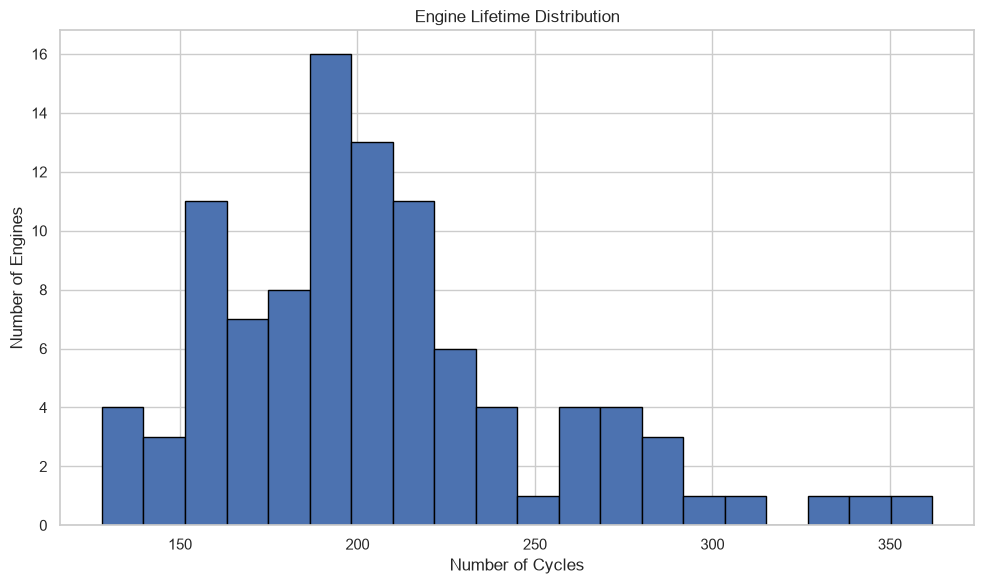

In [10]:
plt.figure(figsize=(10, 6))
plt.hist(engine_lifetime, bins=20, edgecolor="black")

plt.title("Engine Lifetime Distribution")
plt.xlabel("Number of Cycles")
plt.ylabel("Number of Engines")
plt.tight_layout()
plt.show()

## 11. Sensor Summary Statistics

In [11]:
sensor_columns = [col for col in df.columns if col.startswith("sensor_")]
setting_columns = [col for col in df.columns if col.startswith("setting_")]

sensor_summary = df[sensor_columns].describe().T
sensor_summary

,count,mean,std,min,25%,50%,75%,max
sensor_1,20631.0000,518.6700,0.0000,518.6700,518.6700,518.6700,518.6700,518.6700
sensor_2,20631.0000,642.6809,0.5001,641.2100,642.3250,642.6400,643.0000,644.5300
sensor_3,20631.0000,1590.5231,6.1311,1571.0400,1586.2600,1590.1000,1594.3800,1616.9100
sensor_4,20631.0000,1408.9338,9.0006,1382.2500,1402.3600,1408.0400,1414.5550,1441.4900
sensor_5,20631.0000,14.6200,0.0000,14.6200,14.6200,14.6200,14.6200,14.6200
sensor_6,20631.0000,21.6098,0.0014,21.6000,21.6100,21.6100,21.6100,21.6100
sensor_7,20631.0000,553.3677,0.8851,549.8500,552.8100,553.4400,554.0100,556.0600
sensor_8,20631.0000,2388.0967,0.0710,2387.9000,2388.0500,2388.0900,2388.1400,2388.5600
sensor_9,20631.0000,9065.2429,22.0829,9021.7300,9053.1000,9060.6600,9069.4200,9244.5900
sensor_10,20631.0000,1.3000,0.0000,1.3000,1.3000,1.3000,1.3000,1.3000


## 12. Operating Settings Distribution

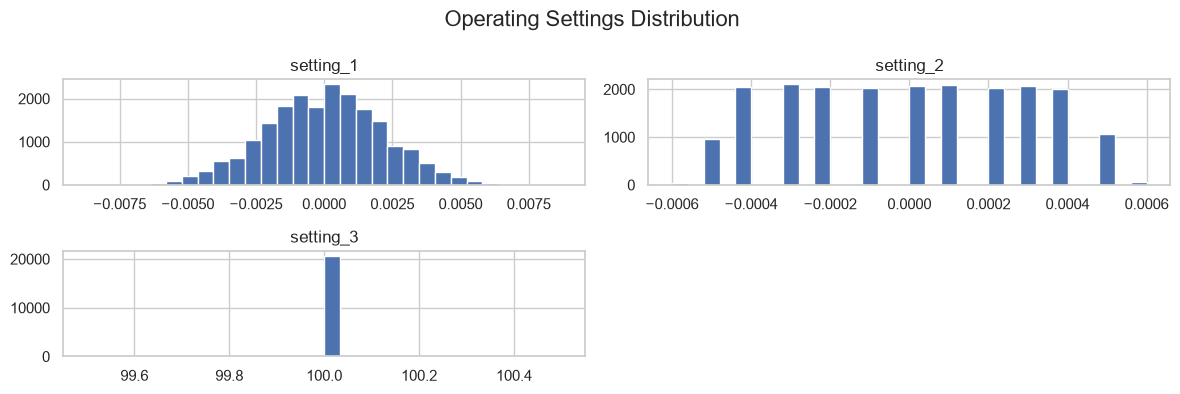

In [12]:
df[setting_columns].hist(figsize=(12, 4), bins=30)
plt.suptitle("Operating Settings Distribution", fontsize=16)
plt.tight_layout()
plt.show()

## 13. Identify Constant Sensors

In [13]:
sensor_unique_values = df[sensor_columns].nunique()
constant_sensors = sensor_unique_values[sensor_unique_values == 1].index.tolist()

print("Number of constant sensors:", len(constant_sensors))
print("Constant sensors:", constant_sensors)

print("\nUnique values per sensor:")
print(sensor_unique_values)

Number of constant sensors: 6
Constant sensors: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']

Unique values per sensor:
sensor_1        1
sensor_2      310
sensor_3     3012
sensor_4     4051
sensor_5        1
sensor_6        2
sensor_7      513
sensor_8       53
sensor_9     6403
sensor_10       1
sensor_11     159
sensor_12     427
sensor_13      56
sensor_14    6078
sensor_15    1918
sensor_16       1
sensor_17      13
sensor_18       1
sensor_19       1
sensor_20     120
sensor_21    4745
dtype: int64


## 14. Sensor Variability

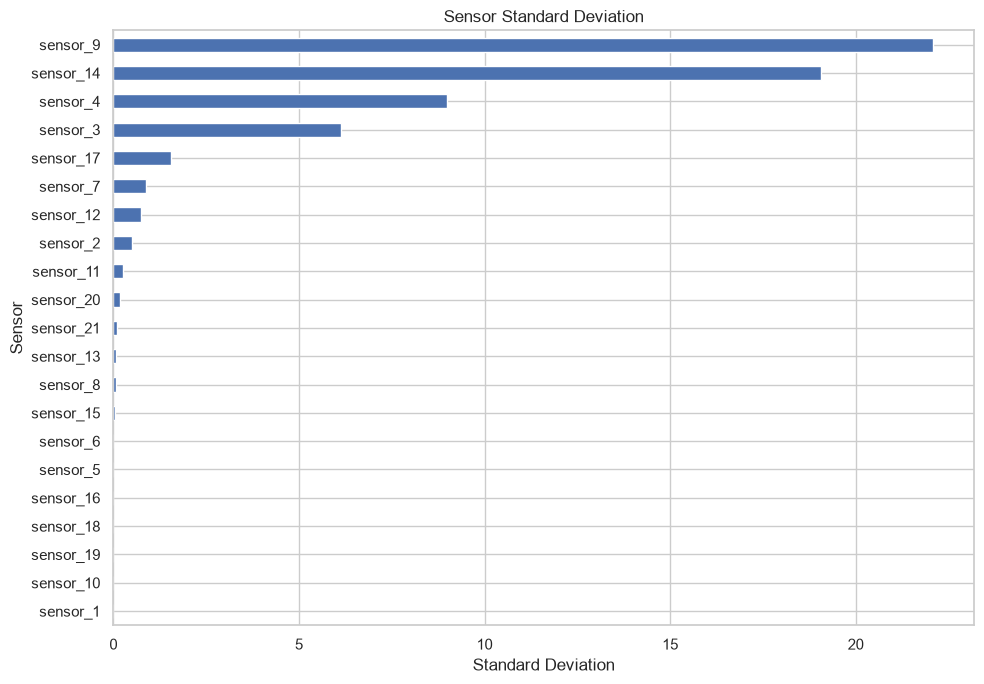

In [14]:
sensor_std = df[sensor_columns].std().sort_values()

plt.figure(figsize=(10, 7))
sensor_std.plot(kind="barh")
plt.title("Sensor Standard Deviation")
plt.xlabel("Standard Deviation")
plt.ylabel("Sensor")
plt.tight_layout()
plt.show()

## 15. Sensor Trajectory for One Engine

In [15]:
# Engine 1 is used as an example to visualize how selected sensors change over cycles.
engine_1 = df[df["engine_id"] == 1].sort_values("cycle")

print("Engine 1 number of cycles:", len(engine_1))
engine_1.head()

Engine 1 number of cycles: 192


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
0,1,1,-0.0007,-0.0004,100.0000,518.6700,641.8200,1589.7000,1400.6000,14.6200,21.6100,554.3600,2388.0600,9046.1900,1.3000,47.4700,521.6600,2388.0200,8138.6200,8.4195,0.0300,392,2388,100.0000,39.0600,23.4190
1,1,2,0.0019,-0.0003,100.0000,518.6700,642.1500,1591.8200,1403.1400,14.6200,21.6100,553.7500,2388.0400,9044.0700,1.3000,47.4900,522.2800,2388.0700,8131.4900,8.4318,0.0300,392,2388,100.0000,39.0000,23.4236
2,1,3,-0.0043,0.0003,100.0000,518.6700,642.3500,1587.9900,1404.2000,14.6200,21.6100,554.2600,2388.0800,9052.9400,1.3000,47.2700,522.4200,2388.0300,8133.2300,8.4178,0.0300,390,2388,100.0000,38.9500,23.3442
3,1,4,0.0007,0.0000,100.0000,518.6700,642.3500,1582.7900,1401.8700,14.6200,21.6100,554.4500,2388.1100,9049.4800,1.3000,47.1300,522.8600,2388.0800,8133.8300,8.3682,0.0300,392,2388,100.0000,38.8800,23.3739
4,1,5,-0.0019,-0.0002,100.0000,518.6700,642.3700,1582.8500,1406.2200,14.6200,21.6100,554.0000,2388.0600,9055.1500,1.3000,47.2800,522.1900,2388.0400,8133.8000,8.4294,0.0300,393,2388,100.0000,38.9000,23.4044


## 16. Plot Selected Sensor Trajectories

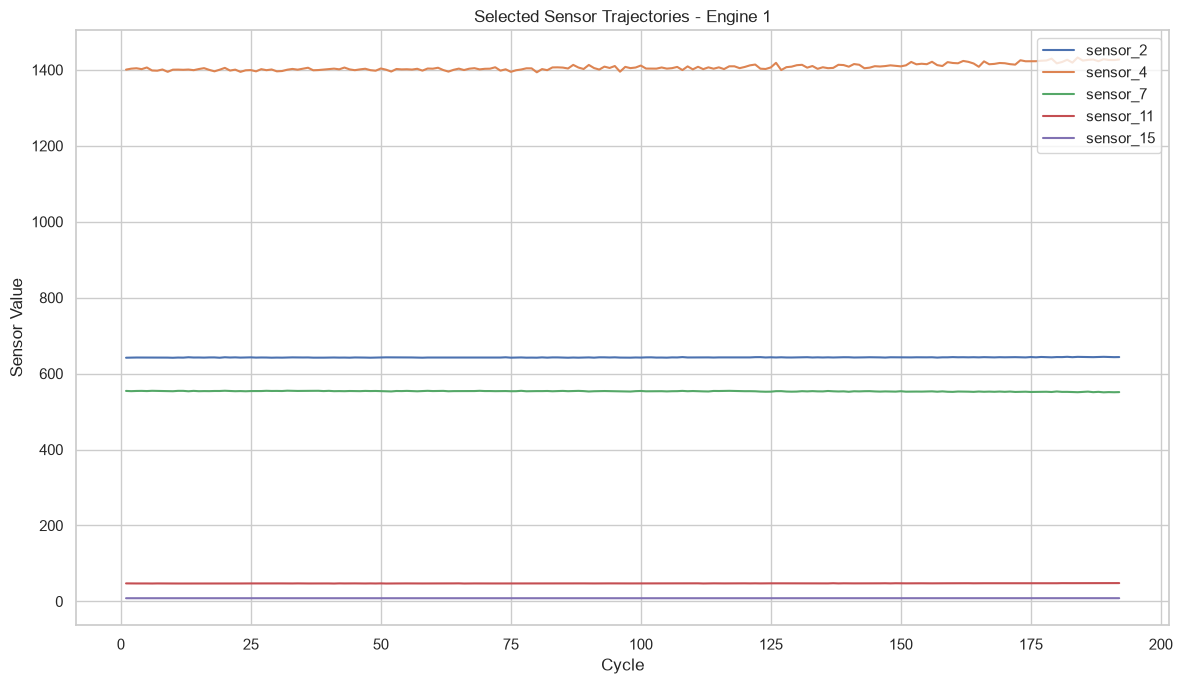

In [16]:
selected_sensors = [
    "sensor_2",
    "sensor_4",
    "sensor_7",
    "sensor_11",
    "sensor_15"
]

plt.figure(figsize=(12, 7))

for sensor in selected_sensors:
    plt.plot(
        engine_1["cycle"],
        engine_1[sensor],
        label=sensor
    )

plt.title("Selected Sensor Trajectories - Engine 1")
plt.xlabel("Cycle")
plt.ylabel("Sensor Value")
plt.legend()
plt.tight_layout()
plt.show()

## 17. Create Lifecycle Progress

In [17]:
# Lifecycle progress is normalized from 0 (early life) to 1 (final observed cycle).
df["lifecycle_progress"] = (
    df["cycle"] /
    df.groupby("engine_id")["cycle"].transform("max")
)

print(df[["engine_id", "cycle", "lifecycle_progress"]].head())
print("Lifecycle progress range:", df["lifecycle_progress"].min(), "to", df["lifecycle_progress"].max())

   engine_id  cycle  lifecycle_progress
0          1      1              0.0052
1          1      2              0.0104
2          1      3              0.0156
3          1      4              0.0208
4          1      5              0.0260
Lifecycle progress range: 0.0027624309392265192 to 1.0


## 18. Mean Sensor Behavior Across Lifecycle Bins

In [18]:
# Continuous lifecycle progress creates many unique values. Binning gives a clearer population-level trend.
bins = np.linspace(0, 1, 11)
labels = [f"{int(bins[i]*100)}-{int(bins[i+1]*100)}%" for i in range(len(bins)-1)]

df["lifecycle_bin"] = pd.cut(
    df["lifecycle_progress"],
    bins=bins,
    labels=labels,
    include_lowest=True
)

lifecycle_means = df.groupby("lifecycle_bin", observed=False)[selected_sensors].mean()
lifecycle_means

,sensor_2,sensor_4,sensor_7,sensor_11,sensor_15
lifecycle_bin,,,,,
0-10%,642.3715,1402.5374,553.9742,47.3468,8.4172
10-20%,642.3846,1402.8011,553.9400,47.3564,8.4185
20-30%,642.4018,1403.3686,553.8859,47.3713,8.4208
30-40%,642.4586,1404.3032,553.8125,47.4007,8.4238
40-50%,642.4951,1405.4128,553.7171,47.4324,8.4270
50-60%,642.5661,1406.9421,553.5675,47.4803,8.4329
60-70%,642.6976,1409.0338,553.3584,47.5467,8.4426
70-80%,642.8439,1412.3986,553.0261,47.6457,8.4567
80-90%,643.0944,1417.2590,552.5757,47.7922,8.4747


## 19. Plot Mean Sensor Behavior Over Lifecycle

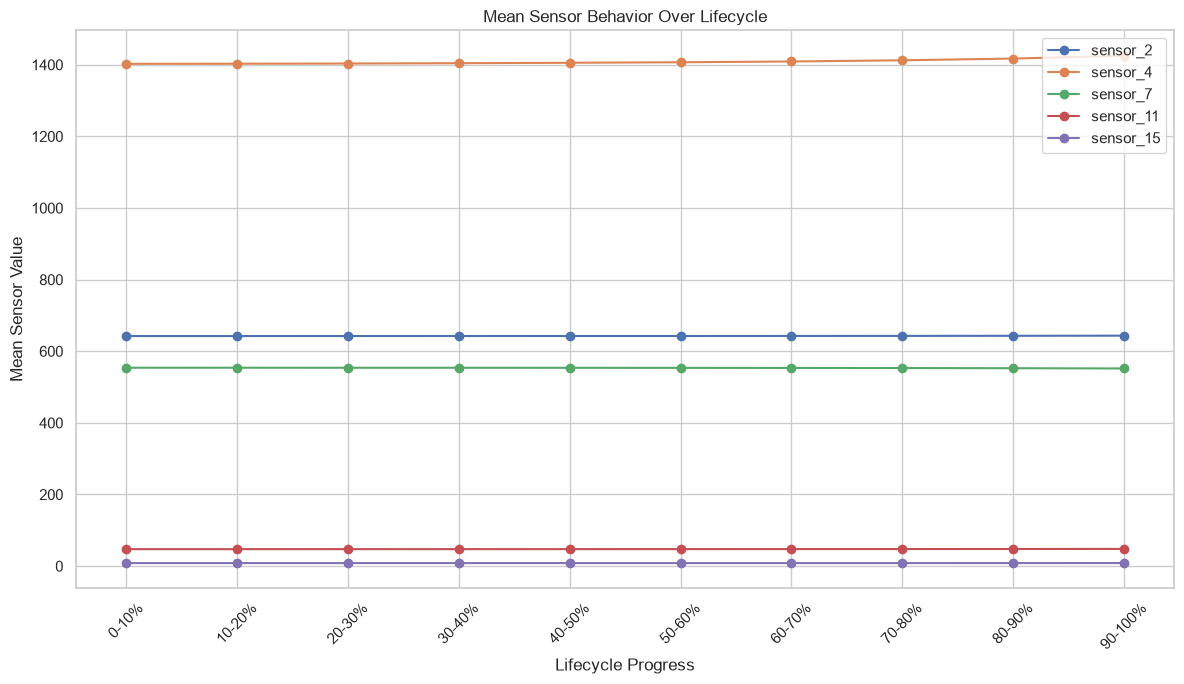

In [19]:
plt.figure(figsize=(12, 7))

x = np.arange(len(lifecycle_means))

for sensor in selected_sensors:
    plt.plot(x, lifecycle_means[sensor], marker="o", label=sensor)

plt.xticks(x, lifecycle_means.index, rotation=45)
plt.title("Mean Sensor Behavior Over Lifecycle")
plt.xlabel("Lifecycle Progress")
plt.ylabel("Mean Sensor Value")
plt.legend()
plt.tight_layout()
plt.show()

## 20. Correlation Analysis

In [20]:
correlation_matrix = df[["cycle"] + sensor_columns].corr()
correlation_matrix.round(3).head()

,cycle,sensor_1,sensor_2,sensor_3,sensor_4,sensor_5,sensor_6,sensor_7,sensor_8,sensor_9,sensor_10,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_16,sensor_17,sensor_18,sensor_19,sensor_20,sensor_21
cycle,1.0000,NaN,0.5500,0.5440,0.6250,NaN,0.1060,-0.5960,0.4760,0.4440,NaN,0.6340,-0.6110,0.4780,0.3700,0.5890,NaN,0.5670,NaN,NaN,-0.5840,-0.5860
sensor_1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
sensor_2,0.5500,NaN,1.0000,0.6030,0.7150,NaN,0.1320,-0.7020,0.6620,0.2740,NaN,0.7400,-0.7250,0.6620,0.1800,0.6760,NaN,0.6300,NaN,NaN,-0.6620,-0.6680
sensor_3,0.5440,NaN,0.6030,1.0000,0.6780,NaN,0.1160,-0.6650,0.6020,0.3230,NaN,0.6960,-0.6800,0.6010,0.2370,0.6400,NaN,0.6000,NaN,NaN,-0.6260,-0.6340
sensor_4,0.6250,NaN,0.7150,0.6780,1.0000,NaN,0.1500,-0.7930,0.7470,0.2970,NaN,0.8300,-0.8160,0.7450,0.1910,0.7580,NaN,0.7030,NaN,NaN,-0.7480,-0.7450


## 21. Sensor Correlation Heatmap

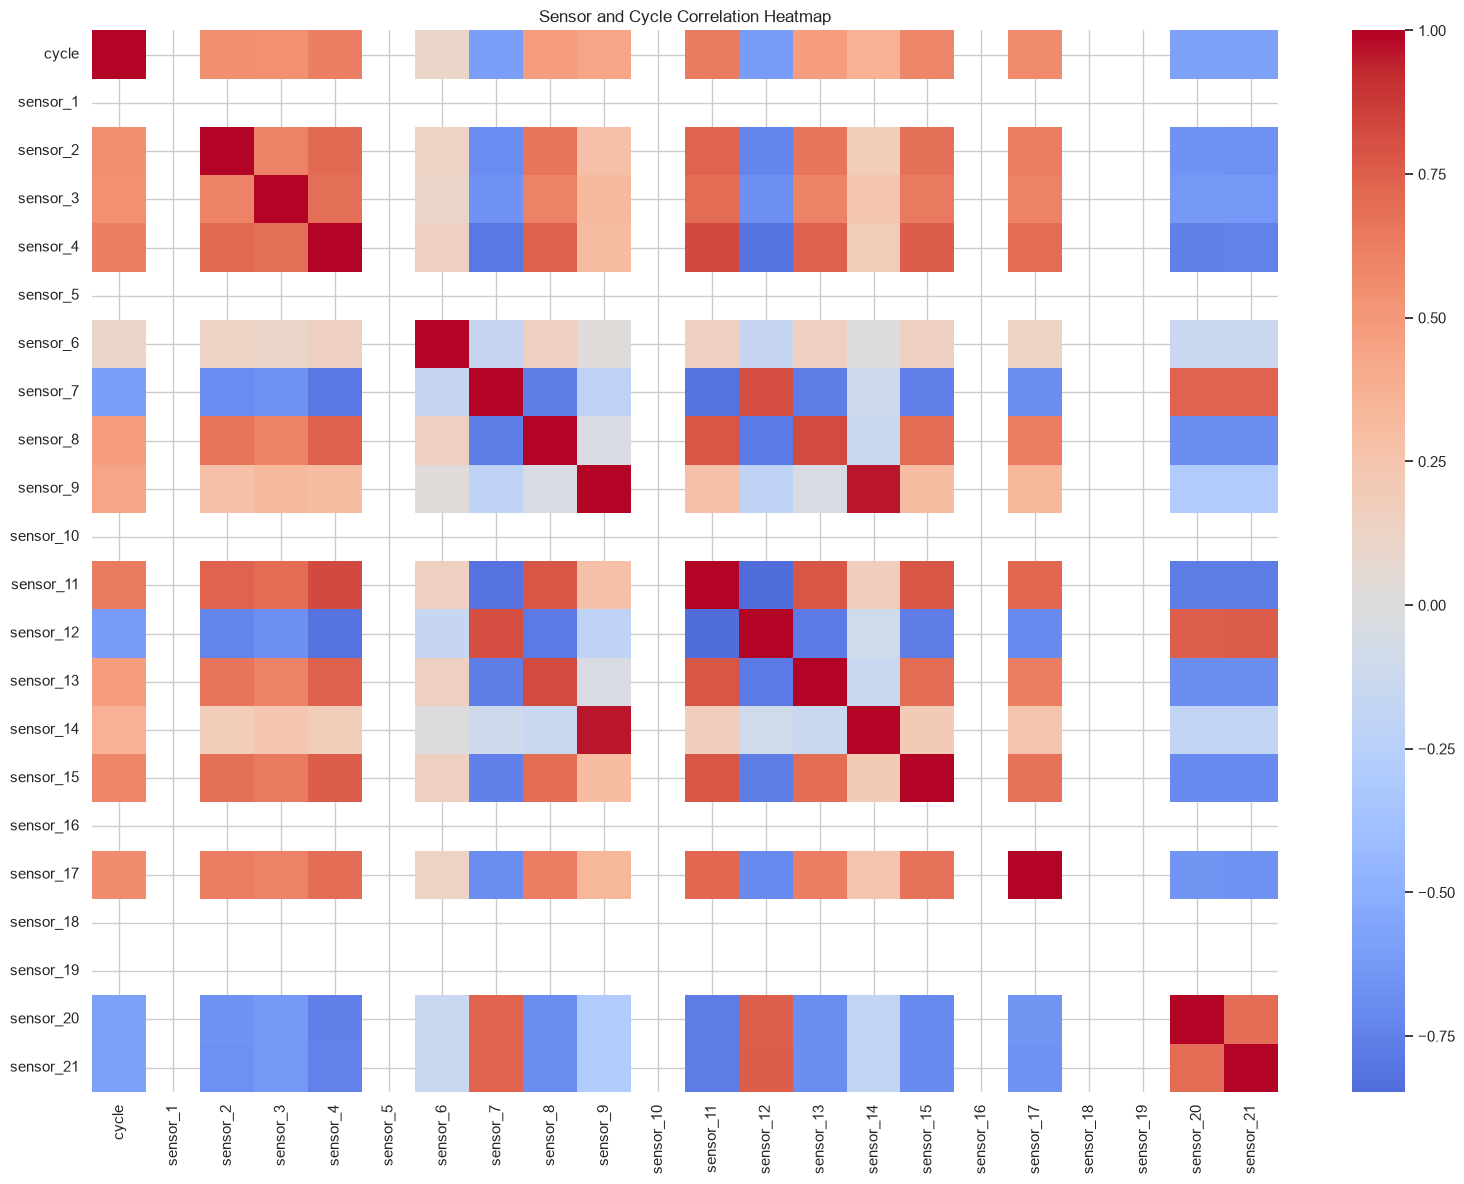

In [21]:
plt.figure(figsize=(16, 12))

sns.heatmap(
    correlation_matrix,
    cmap="coolwarm",
    center=0,
    square=False
)

plt.title("Sensor and Cycle Correlation Heatmap")
plt.tight_layout()
plt.show()

## 22. Create Training RUL Target

In [22]:
# RUL = final observed cycle of the engine - current cycle.
df["RUL"] = (
    df.groupby("engine_id")["cycle"].transform("max")
    - df["cycle"]
)

print("RUL range:", df["RUL"].min(), "to", df["RUL"].max())
df[["engine_id", "cycle", "RUL"]].head(10)

RUL range: 0 to 361


,engine_id,cycle,RUL
0,1,1,191
1,1,2,190
2,1,3,189
3,1,4,188
4,1,5,187
5,1,6,186
6,1,7,185
7,1,8,184
8,1,9,183
9,1,10,182


## 23. Validate RUL Calculation

In [23]:
# The final row of every training engine should have RUL = 0.
last_rows = df.groupby("engine_id")["cycle"].idxmax()
final_rul_values = df.loc[last_rows, "RUL"]

print("Unique RUL values at each engine's final cycle:", final_rul_values.unique())
assert (final_rul_values == 0).all(), "RUL validation failed: some final cycles do not have RUL = 0."

Unique RUL values at each engine's final cycle: [0]


## 24. RUL Distribution

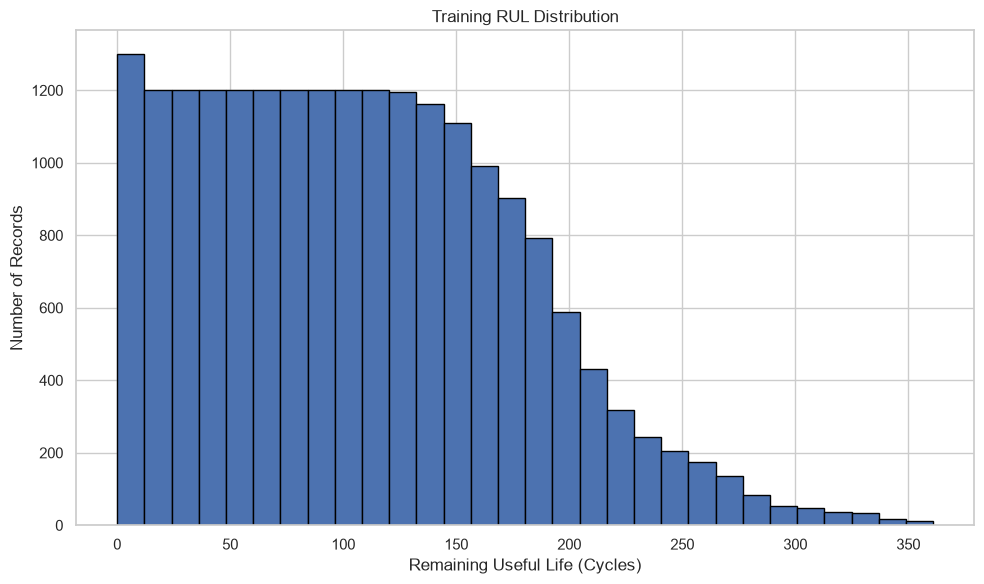

In [24]:
plt.figure(figsize=(10, 6))
plt.hist(df["RUL"], bins=30, edgecolor="black")

plt.title("Training RUL Distribution")
plt.xlabel("Remaining Useful Life (Cycles)")
plt.ylabel("Number of Records")
plt.tight_layout()
plt.show()

## 25. Sensor-RUL Correlation

In [25]:
# Constant sensors have no variance, so their correlation with RUL is undefined.
non_constant_sensors = [s for s in sensor_columns if s not in constant_sensors]

rul_correlation = (
    df[non_constant_sensors + ["RUL"]]
    .corr()["RUL"]
    .drop("RUL")
    .sort_values()
)

rul_correlation

sensor_11   -0.6962
sensor_4    -0.6789
sensor_15   -0.6427
sensor_2    -0.6065
sensor_17   -0.6062
sensor_3    -0.5845
sensor_8    -0.5640
sensor_13   -0.5626
sensor_9    -0.3901
sensor_14   -0.3068
sensor_6    -0.1283
sensor_20    0.6294
sensor_21    0.6357
sensor_7     0.6572
sensor_12    0.6720
Name: RUL, dtype: float64

## 26. Visualize Sensor-RUL Correlation

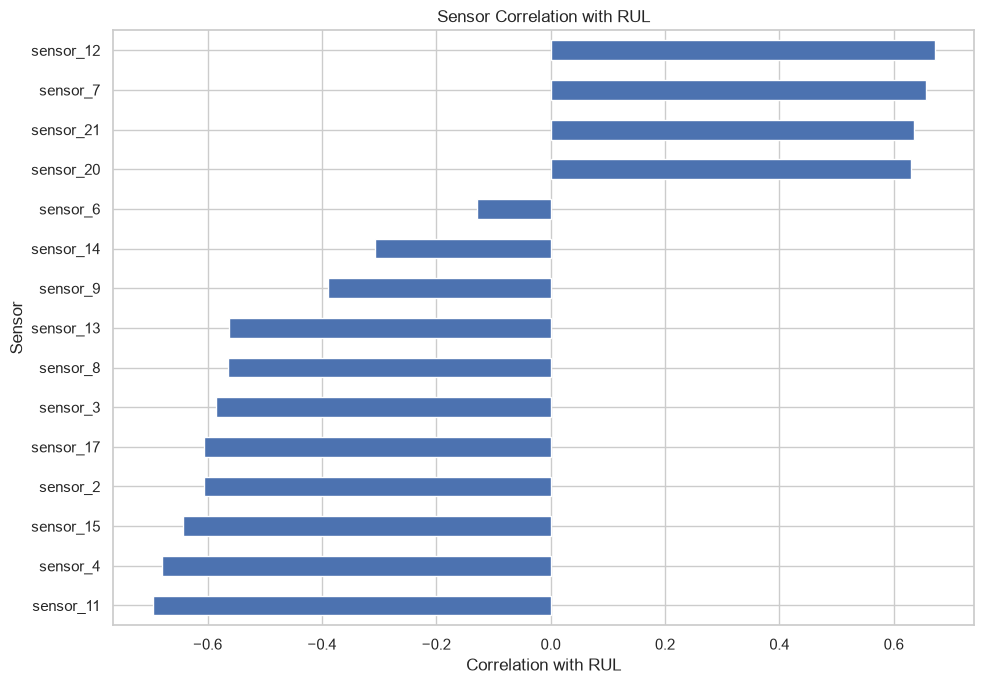

In [26]:
plt.figure(figsize=(10, 7))
rul_correlation.plot(kind="barh")

plt.title("Sensor Correlation with RUL")
plt.xlabel("Correlation with RUL")
plt.ylabel("Sensor")
plt.tight_layout()
plt.show()

## 27. Top Sensors by Absolute RUL Correlation

In [27]:
top_rul_sensors = (
    rul_correlation.abs()
    .sort_values(ascending=False)
    .head(10)
)

print("Top 10 sensors by absolute correlation with RUL:")
print(top_rul_sensors)

Top 10 sensors by absolute correlation with RUL:
sensor_11   0.6962
sensor_4    0.6789
sensor_12   0.6720
sensor_7    0.6572
sensor_15   0.6427
sensor_21   0.6357
sensor_20   0.6294
sensor_2    0.6065
sensor_17   0.6062
sensor_3    0.5845
Name: RUL, dtype: float64


## 28. Outlier Inspection with IQR

In [28]:
# This step identifies unusual values for inspection only.
# We do NOT automatically remove them because extreme sensor values can represent real degradation behavior.

def iqr_outlier_count(series):
    q1 = series.quantile(0.25)
    q3 = series.quantile(0.75)
    iqr = q3 - q1
    lower = q1 - 1.5 * iqr
    upper = q3 + 1.5 * iqr
    return ((series < lower) | (series > upper)).sum()

outlier_counts = df[non_constant_sensors].apply(iqr_outlier_count).sort_values(ascending=False)

outlier_summary = pd.DataFrame({
    "outlier_count": outlier_counts,
    "outlier_percentage": (outlier_counts / len(df) * 100).round(2)
})

outlier_summary

,outlier_count,outlier_percentage
sensor_9,1686,8.1700
sensor_14,1543,7.4800
sensor_6,406,1.9700
sensor_8,320,1.5500
sensor_11,167,0.8100
sensor_3,165,0.8000
sensor_13,161,0.7800
sensor_12,146,0.7100
sensor_21,136,0.6600
sensor_2,128,0.6200


## 29. Visualize Potential Outliers

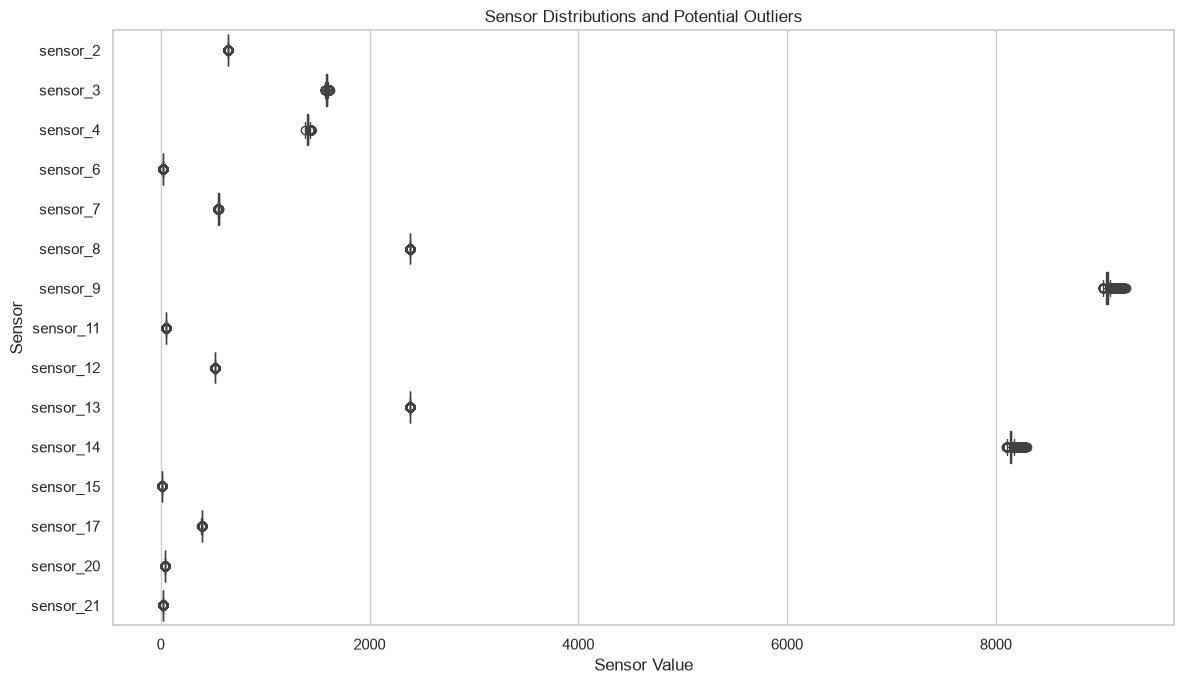

In [29]:
plt.figure(figsize=(12, 7))

sns.boxplot(data=df[non_constant_sensors], orient="h")
plt.title("Sensor Distributions and Potential Outliers")
plt.xlabel("Sensor Value")
plt.ylabel("Sensor")
plt.tight_layout()
plt.show()

## 30. Remove Constant Sensors

In [30]:
# Constant sensors do not provide useful variation for RUL prediction.
df_clean = df.drop(columns=constant_sensors).copy()

print("Constant sensors removed:", constant_sensors)
print("Original shape:", df.shape)
print("Shape after removing constant sensors:", df_clean.shape)

Constant sensors removed: ['sensor_1', 'sensor_5', 'sensor_10', 'sensor_16', 'sensor_18', 'sensor_19']
Original shape: (20631, 29)
Shape after removing constant sensors: (20631, 23)


## 31. Final ML Feature List

In [31]:
# Keep engine_id and cycle for sequence/time information.
# lifecycle_progress and lifecycle_bin are EDA helper columns and should not be used blindly as model features.
feature_columns = [
    "engine_id",
    "cycle",
    *setting_columns,
    *non_constant_sensors
]

print("Number of ML feature columns:", len(feature_columns))
print(feature_columns)

Number of ML feature columns: 20
['engine_id', 'cycle', 'setting_1', 'setting_2', 'setting_3', 'sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


## 32. Final Dataset Quality Check

In [32]:
print("Final dataset shape:", df_clean.shape)
print("Missing values:", df_clean.isnull().sum().sum())
print("Duplicate rows:", df_clean.duplicated().sum())
print("RUL minimum:", df_clean["RUL"].min())
print("RUL maximum:", df_clean["RUL"].max())

assert df_clean.isnull().sum().sum() == 0, "Missing values remain in the cleaned dataset."
assert df_clean["RUL"].min() == 0, "RUL minimum should be 0."

Final dataset shape: (20631, 23)
Missing values: 0
Duplicate rows: 0
RUL minimum: 0
RUL maximum: 361


## 33. ML-Ready Dataset Preview

In [33]:
ml_ready_df = df_clean[feature_columns + ["RUL"]].copy()

print("ML-ready dataset shape:", ml_ready_df.shape)
ml_ready_df.head()

ML-ready dataset shape: (20631, 21)


,engine_id,cycle,setting_1,setting_2,setting_3,sensor_2,sensor_3,sensor_4,sensor_6,sensor_7,sensor_8,sensor_9,sensor_11,sensor_12,sensor_13,sensor_14,sensor_15,sensor_17,sensor_20,sensor_21,RUL
0,1,1,-0.0007,-0.0004,100.0000,641.8200,1589.7000,1400.6000,21.6100,554.3600,2388.0600,9046.1900,47.4700,521.6600,2388.0200,8138.6200,8.4195,392,39.0600,23.4190,191
1,1,2,0.0019,-0.0003,100.0000,642.1500,1591.8200,1403.1400,21.6100,553.7500,2388.0400,9044.0700,47.4900,522.2800,2388.0700,8131.4900,8.4318,392,39.0000,23.4236,190
2,1,3,-0.0043,0.0003,100.0000,642.3500,1587.9900,1404.2000,21.6100,554.2600,2388.0800,9052.9400,47.2700,522.4200,2388.0300,8133.2300,8.4178,390,38.9500,23.3442,189
3,1,4,0.0007,0.0000,100.0000,642.3500,1582.7900,1401.8700,21.6100,554.4500,2388.1100,9049.4800,47.1300,522.8600,2388.0800,8133.8300,8.3682,392,38.8800,23.3739,188
4,1,5,-0.0019,-0.0002,100.0000,642.3700,1582.8500,1406.2200,21.6100,554.0000,2388.0600,9055.1500,47.2800,522.1900,2388.0400,8133.8000,8.4294,393,38.9000,23.4044,187


## 34. EDA Summary

In [34]:
print("=" * 60)
print("NASA C-MAPSS FD001 EDA SUMMARY")
print("=" * 60)
print(f"Total records: {len(df):,}")
print(f"Number of engines: {df['engine_id'].nunique()}")
print(f"Number of sensors: {len(sensor_columns)}")
print(f"Constant sensors removed: {len(constant_sensors)}")
print(f"Remaining sensors: {len(non_constant_sensors)}")
print(f"RUL range: {df['RUL'].min()} - {df['RUL'].max()} cycles")
print(f"Missing values: {df.isnull().sum().sum()}")
print(f"Duplicate rows: {df.duplicated().sum()}")
print("\nEDA completed successfully. The dataset is ready for the next modeling stage.")

NASA C-MAPSS FD001 EDA SUMMARY
Total records: 20,631
Number of engines: 100
Number of sensors: 21
Constant sensors removed: 6
Remaining sensors: 15
RUL range: 0 - 361 cycles
Missing values: 0
Duplicate rows: 0

EDA completed successfully. The dataset is ready for the next modeling stage.


# Machine Learning Modeling

## ML Data Preparation

In [35]:
# Define features and target

X = df[non_constant_sensors].copy()
y = df["RUL"].copy()

print("ML Data Preparation")
print("=" * 50)

print(f"Feature matrix shape: {X.shape}")
print(f"Target shape: {y.shape}")

print("\nFeatures:")
print(non_constant_sensors)

print("\nTarget:")
print("RUL")

print("\nMissing values in X:", X.isnull().sum().sum())
print("Missing values in y:", y.isnull().sum())

ML Data Preparation
Feature matrix shape: (20631, 15)
Target shape: (20631,)

Features:
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']

Target:
RUL

Missing values in X: 0
Missing values in y: 0


In [36]:
from sklearn.model_selection import GroupShuffleSplit

# Group-based train/validation split
gss = GroupShuffleSplit(
    n_splits=1,
    test_size=0.20,
    random_state=42
)

train_idx, val_idx = next(
    gss.split(X, y, groups=df["engine_id"])
)

X_train = X.iloc[train_idx].copy()
X_val = X.iloc[val_idx].copy()

y_train = y.iloc[train_idx].copy()
y_val = y.iloc[val_idx].copy()

train_engines = df.iloc[train_idx]["engine_id"].unique()
val_engines = df.iloc[val_idx]["engine_id"].unique()

print("Train/Validation Split")
print("=" * 50)

print(f"Training records: {len(X_train):,}")
print(f"Validation records: {len(X_val):,}")

print(f"\nTraining engines: {len(train_engines)}")
print(f"Validation engines: {len(val_engines)}")

print(f"\nTraining engine IDs:")
print(sorted(train_engines))

print(f"\nValidation engine IDs:")
print(sorted(val_engines))

print("\nEngine overlap:")
print(set(train_engines).intersection(set(val_engines)))

Train/Validation Split
Training records: 16,561
Validation records: 4,070

Training engines: 80
Validation engines: 20

Training engine IDs:
[np.int64(2), np.int64(3), np.int64(4), np.int64(6), np.int64(7), np.int64(8), np.int64(9), np.int64(10), np.int64(12), np.int64(14), np.int64(15), np.int64(16), np.int64(17), np.int64(18), np.int64(20), np.int64(21), np.int64(22), np.int64(24), np.int64(25), np.int64(26), np.int64(27), np.int64(28), np.int64(29), np.int64(30), np.int64(33), np.int64(35), np.int64(36), np.int64(37), np.int64(38), np.int64(39), np.int64(41), np.int64(42), np.int64(43), np.int64(44), np.int64(47), np.int64(48), np.int64(49), np.int64(50), np.int64(51), np.int64(52), np.int64(53), np.int64(55), np.int64(56), np.int64(57), np.int64(58), np.int64(59), np.int64(60), np.int64(61), np.int64(62), np.int64(63), np.int64(64), np.int64(65), np.int64(66), np.int64(67), np.int64(68), np.int64(69), np.int64(70), np.int64(72), np.int64(73), np.int64(75), np.int64(76), np.int64(79

In [37]:
#Feature Scaling
from sklearn.preprocessing import StandardScaler

# Initialize scaler
scaler = StandardScaler()

# Fit only on training data
X_train_scaled = scaler.fit_transform(X_train)

# Transform validation data using the same scaler
X_val_scaled = scaler.transform(X_val)

print("Feature Scaling")
print("=" * 50)

print(f"X_train_scaled shape: {X_train_scaled.shape}")
print(f"X_val_scaled shape: {X_val_scaled.shape}")

print("\nTraining mean (first 5 features):")
print(X_train_scaled.mean(axis=0)[:5])

print("\nTraining standard deviation (first 5 features):")
print(X_train_scaled.std(axis=0)[:5])

Feature Scaling
X_train_scaled shape: (16561, 15)
X_val_scaled shape: (4070, 15)

Training mean (first 5 features):
[-2.19757255e-14 -1.42185775e-14 -4.40029364e-15 -3.89931060e-12
 -4.51802381e-14]

Training standard deviation (first 5 features):
[1. 1. 1. 1. 1.]


## LinearRegression

In [38]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Initialize Linear Regression
lr_model = LinearRegression()

# Train the model
lr_model.fit(X_train_scaled, y_train)

# Make predictions
y_pred_lr = lr_model.predict(X_val_scaled)

# Evaluate
mae_lr = mean_absolute_error(y_val, y_pred_lr)
rmse_lr = np.sqrt(mean_squared_error(y_val, y_pred_lr))
r2_lr = r2_score(y_val, y_pred_lr)

print("Linear Regression Results")
print("=" * 50)
print(f"MAE  : {mae_lr:.4f}")
print(f"RMSE : {rmse_lr:.4f}")
print(f"R²   : {r2_lr:.4f}")

Linear Regression Results
MAE  : 30.1015
RMSE : 38.1239
R²   : 0.6628


## RandomForestRegressor

In [39]:
from sklearn.ensemble import RandomForestRegressor

# Initialize Random Forest
rf_model = RandomForestRegressor(
    n_estimators=200,
    max_depth=None,
    min_samples_split=2,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

# Train
rf_model.fit(X_train, y_train)

# Predict
y_pred_rf = rf_model.predict(X_val)

# Evaluate
mae_rf = mean_absolute_error(y_val, y_pred_rf)
rmse_rf = np.sqrt(mean_squared_error(y_val, y_pred_rf))
r2_rf = r2_score(y_val, y_pred_rf)

print("Random Forest Results")
print("=" * 50)
print(f"MAE  : {mae_rf:.4f}")
print(f"RMSE : {rmse_rf:.4f}")
print(f"R²   : {r2_rf:.4f}")

Random Forest Results
MAE  : 25.8620
RMSE : 35.3491
R²   : 0.7101


## XGBoost

In [40]:
from xgboost import XGBRegressor

# Initialize XGBoost
xgb_model = XGBRegressor(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    n_jobs=-1
)

# Train
xgb_model.fit(X_train, y_train)

# Predict
y_pred_xgb = xgb_model.predict(X_val)

# Evaluate
mae_xgb = mean_absolute_error(y_val, y_pred_xgb)
rmse_xgb = np.sqrt(mean_squared_error(y_val, y_pred_xgb))
r2_xgb = r2_score(y_val, y_pred_xgb)

print("XGBoost Results")
print("=" * 50)
print(f"MAE  : {mae_xgb:.4f}")
print(f"RMSE : {rmse_xgb:.4f}")
print(f"R²   : {r2_xgb:.4f}")

XGBoost Results
MAE  : 25.6385
RMSE : 35.2748
R²   : 0.7113


In [41]:
model_results = pd.DataFrame({
    "Model": [
        "Linear Regression",
        "Random Forest",
        "XGBoost"
    ],
    "MAE": [
        mae_lr,
        mae_rf,
        mae_xgb
    ],
    "RMSE": [
        rmse_lr,
        rmse_rf,
        rmse_xgb
    ],
    "R2": [
        r2_lr,
        r2_rf,
        r2_xgb
    ]
})

model_results = model_results.sort_values("MAE")

print("Model Comparison")
print("=" * 60)
display(model_results.round(4))

Model Comparison


,Model,MAE,RMSE,R2
2,XGBoost,25.6385,35.2748,0.7113
1,Random Forest,25.8620,35.3491,0.7101
0,Linear Regression,30.1015,38.1239,0.6628


In [42]:
from xgboost import XGBRegressor
from sklearn.model_selection import RandomizedSearchCV

# Base XGBoost model
xgb_base = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

# Hyperparameter search space
param_grid = {
    "n_estimators": [100, 200, 300, 400],
    "max_depth": [3, 4, 5, 6],
    "learning_rate": [0.01, 0.03, 0.05, 0.1],
    "subsample": [0.7, 0.8, 0.9, 1.0],
    "colsample_bytree": [0.7, 0.8, 0.9, 1.0],
    "min_child_weight": [1, 3, 5],
    "gamma": [0, 0.1, 0.2],
}

# Randomized search
random_search = RandomizedSearchCV(
    estimator=xgb_base,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=3,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

# Run tuning
random_search.fit(X_train, y_train)

print("Best Parameters:")
print(random_search.best_params_)

print("\nBest Cross-Validation MAE:")
print(-random_search.best_score_)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


Best Parameters:
{'subsample': 0.9, 'n_estimators': 100, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.05, 'gamma': 0, 'colsample_bytree': 0.7}

Best Cross-Validation MAE:
31.53314717610677


In [43]:
# Tuned XGBoost Model Evaluation

best_xgb = random_search.best_estimator_

y_pred_xgb_tuned = best_xgb.predict(X_val)

mae_xgb_tuned = mean_absolute_error(y_val, y_pred_xgb_tuned)
rmse_xgb_tuned = np.sqrt(mean_squared_error(y_val, y_pred_xgb_tuned))
r2_xgb_tuned = r2_score(y_val, y_pred_xgb_tuned)

print("Tuned XGBoost Results")
print("=" * 40)
print(f"MAE  : {mae_xgb_tuned:.4f}")
print(f"RMSE : {rmse_xgb_tuned:.4f}")
print(f"R²   : {r2_xgb_tuned:.4f}")

Tuned XGBoost Results
MAE  : 25.7976
RMSE : 35.1660
R²   : 0.7131


In [44]:
from sklearn.model_selection import GroupKFold, RandomizedSearchCV
from xgboost import XGBRegressor
train_groups = df.iloc[train_idx]["engine_id"].values

print("Number of training groups:", len(np.unique(train_groups)))
group_kfold = GroupKFold(n_splits=3)

Number of training groups: 80


In [45]:
xgb_group_base = XGBRegressor(
    objective="reg:squarederror",
    random_state=42,
    n_jobs=-1
)

group_random_search = RandomizedSearchCV(
    estimator=xgb_group_base,
    param_distributions=param_grid,
    n_iter=20,
    scoring="neg_mean_absolute_error",
    cv=group_kfold,
    verbose=1,
    random_state=42,
    n_jobs=-1
)

group_random_search.fit(
    X_train,
    y_train,
    groups=train_groups
)

Fitting 3 folds for each of 20 candidates, totalling 60 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.","XGBRegressor(...ree=None, ...)"
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'colsample_bytree': [0.7, 0.8, ...], 'gamma': [0, 0.1, ...], 'learning_rate': [0.01, 0.03, ...], 'max_depth': [3, 4, ...], ...}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",20
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_mean_absolute_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",GroupKFold(n_...shuffle=False)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",42
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator,

In [46]:
print("Best GroupKFold Parameters:")
print(group_random_search.best_params_)

print("\nBest GroupKFold Cross-Validation MAE:")
print(-group_random_search.best_score_)

Best GroupKFold Parameters:
{'subsample': 0.7, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.01, 'gamma': 0.1, 'colsample_bytree': 0.7}

Best GroupKFold Cross-Validation MAE:
31.269074122111004


In [47]:
# Final GroupKFold Tuned XGBoost Evaluation

best_xgb_group = group_random_search.best_estimator_

y_pred_xgb_group = best_xgb_group.predict(X_val)

mae_xgb_group = mean_absolute_error(y_val, y_pred_xgb_group)
rmse_xgb_group = np.sqrt(mean_squared_error(y_val, y_pred_xgb_group))
r2_xgb_group = r2_score(y_val, y_pred_xgb_group)

print("GroupKFold Tuned XGBoost Results")
print("=" * 45)
print(f"MAE  : {mae_xgb_group:.4f}")
print(f"RMSE : {rmse_xgb_group:.4f}")
print(f"R²   : {r2_xgb_group:.4f}")

GroupKFold Tuned XGBoost Results
MAE  : 25.8786
RMSE : 35.1955
R²   : 0.7126


## Final Model

The GroupKFold-tuned XGBoost (`best_xgb_group`) is the final model. All analysis below and the saved model file use it.

In [48]:
# Final model used for analysis, export, and the Streamlit app.
final_model = best_xgb_group
y_pred_final = y_pred_xgb_group

print("Final model: GroupKFold-tuned XGBoost")
print("Hyperparameters:", group_random_search.best_params_)


Final model: GroupKFold-tuned XGBoost
Hyperparameters: {'subsample': 0.7, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.01, 'gamma': 0.1, 'colsample_bytree': 0.7}


In [49]:
# XGBoost Feature Importance

feature_importance = pd.DataFrame({
    "Feature": X_train.columns,
    "Importance": final_model.feature_importances_
})

feature_importance = feature_importance.sort_values(
    by="Importance",
    ascending=False
)

print("Final XGBoost Feature Importance")
print("=" * 45)
display(feature_importance.round(4))

Final XGBoost Feature Importance


,Feature,Importance
7,sensor_11,0.3334
2,sensor_4,0.2234
8,sensor_12,0.0960
4,sensor_7,0.0763
6,sensor_9,0.0561
11,sensor_15,0.0390
13,sensor_20,0.0329
10,sensor_14,0.0314
14,sensor_21,0.0294
12,sensor_17,0.0203


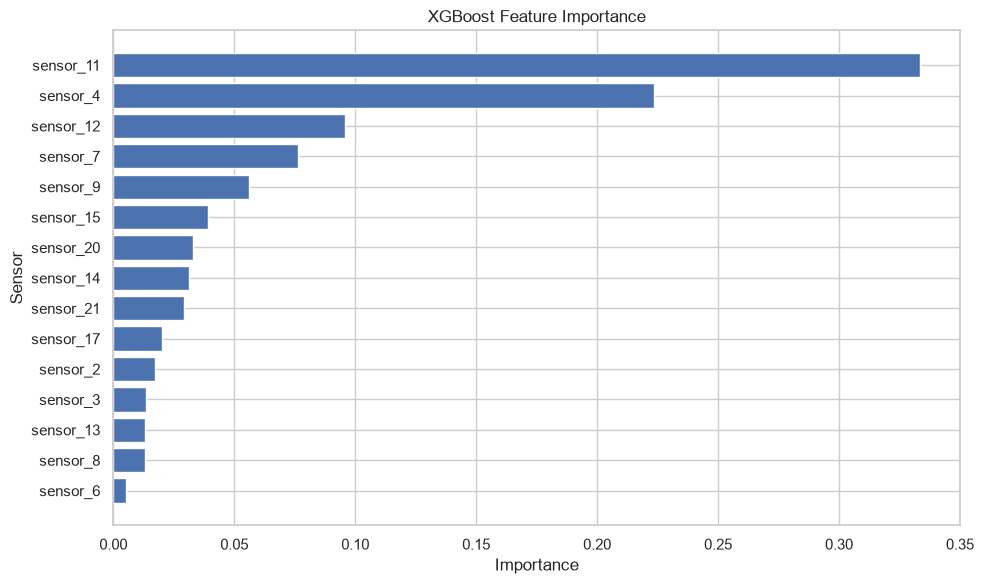

In [50]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    feature_importance["Feature"],
    feature_importance["Importance"]
)

plt.gca().invert_yaxis()

plt.xlabel("Importance")
plt.ylabel("Sensor")
plt.title("XGBoost Feature Importance")

plt.tight_layout()
plt.show()

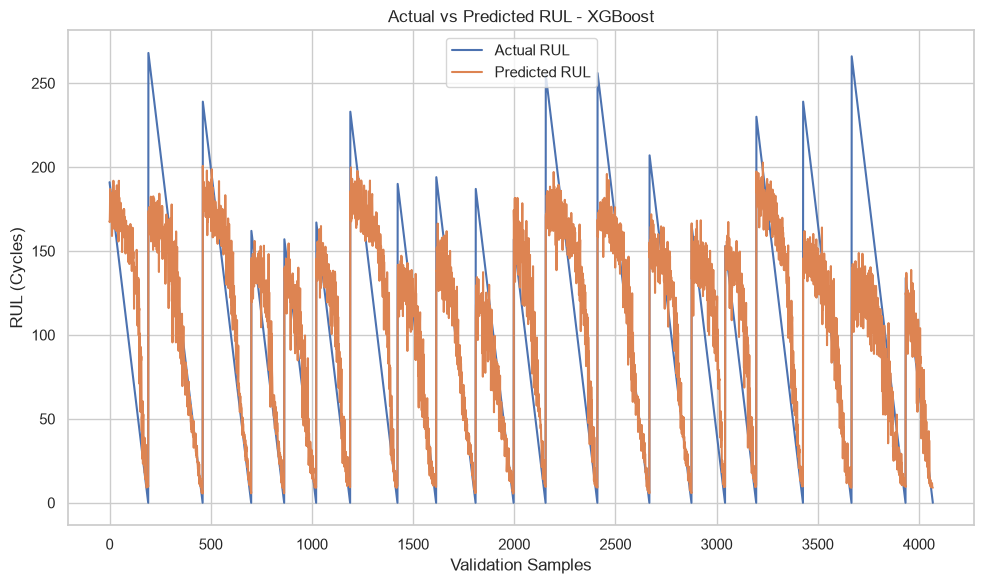

In [51]:
# Actual vs Predicted RUL

plt.figure(figsize=(10, 6))

plt.plot(
    y_val.values,
    label="Actual RUL"
)

plt.plot(
    y_pred_final,
    label="Predicted RUL"
)

plt.xlabel("Validation Samples")
plt.ylabel("RUL (Cycles)")
plt.title("Actual vs Predicted RUL - XGBoost")

plt.legend()
plt.tight_layout()
plt.show()

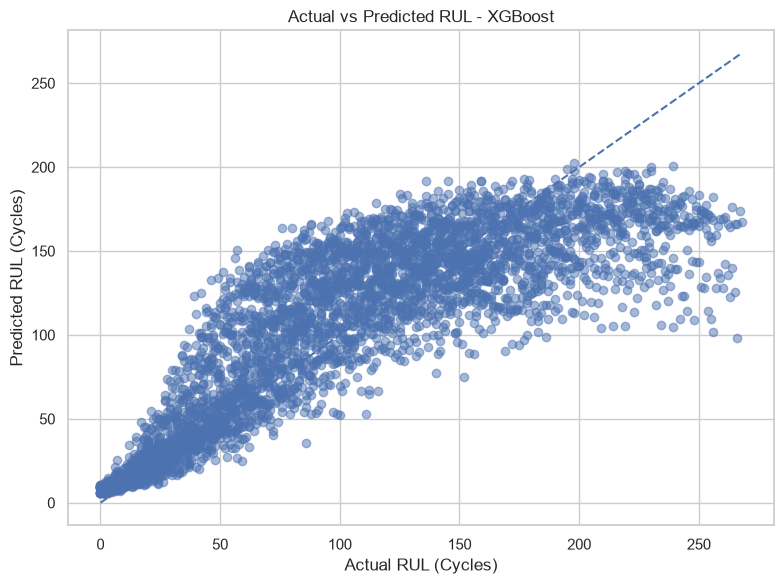

In [52]:
# Actual vs Predicted RUL Scatter Plot

plt.figure(figsize=(8, 6))

plt.scatter(
    y_val,
    y_pred_final,
    alpha=0.5
)

# Perfect prediction line
min_rul = min(y_val.min(), y_pred_final.min())
max_rul = max(y_val.max(), y_pred_final.max())

plt.plot(
    [min_rul, max_rul],
    [min_rul, max_rul],
    linestyle="--"
)

plt.xlabel("Actual RUL (Cycles)")
plt.ylabel("Predicted RUL (Cycles)")
plt.title("Actual vs Predicted RUL - XGBoost")

plt.tight_layout()
plt.show()

In [53]:
# Prediction Error / Residual Analysis

errors = y_val - y_pred_final

print("Prediction Error Statistics")
print("=" * 45)
print(f"Mean Error   : {errors.mean():.4f}")
print(f"Mean Abs Error: {np.abs(errors).mean():.4f}")
print(f"Minimum Error: {errors.min():.4f}")
print(f"Maximum Error: {errors.max():.4f}")

Prediction Error Statistics
Mean Error   : -1.5980
Mean Abs Error: 25.8786
Minimum Error: -93.6865
Maximum Error: 167.9073


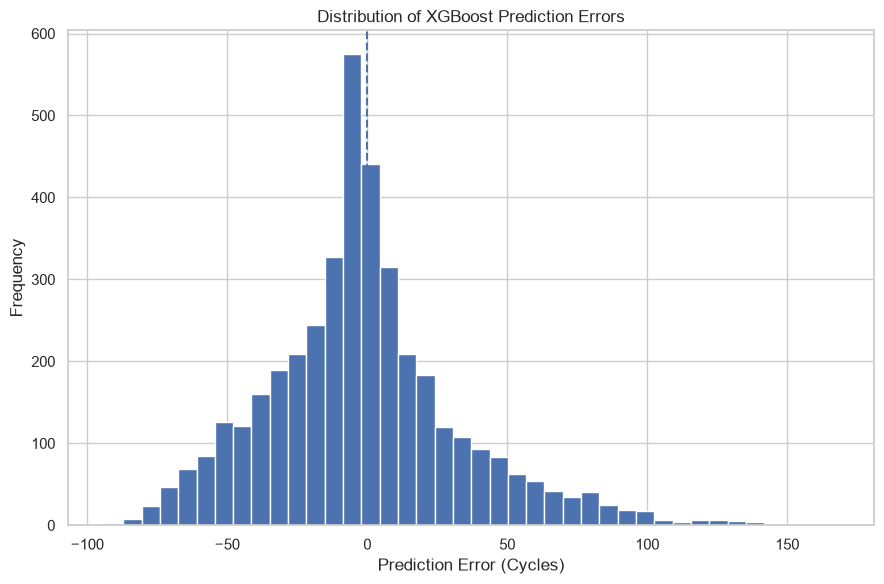

In [54]:
plt.figure(figsize=(9, 6))

plt.hist(errors, bins=40)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Prediction Error (Cycles)")
plt.ylabel("Frequency")
plt.title("Distribution of XGBoost Prediction Errors")

plt.tight_layout()
plt.show()

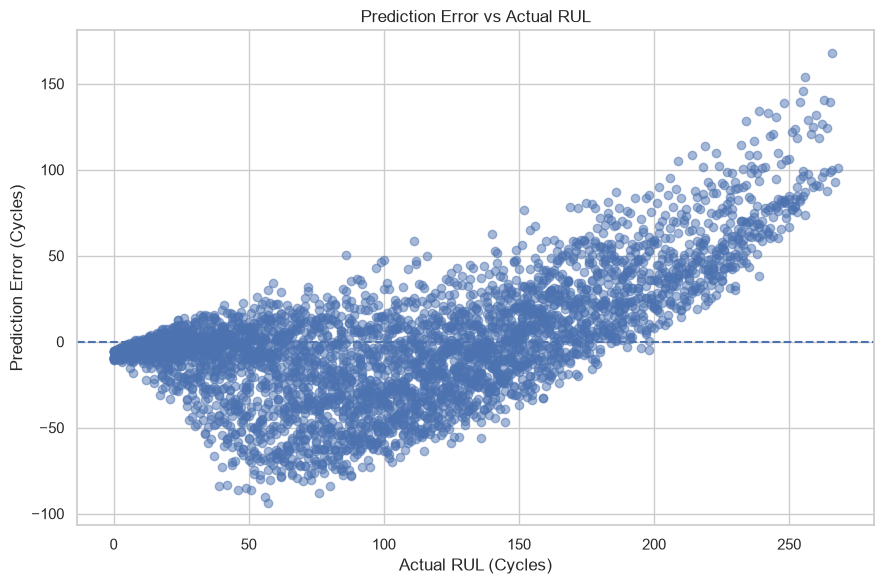

In [55]:
plt.figure(figsize=(9, 6))

plt.scatter(
    y_val,
    errors,
    alpha=0.5
)

plt.axhline(
    0,
    linestyle="--"
)

plt.xlabel("Actual RUL (Cycles)")
plt.ylabel("Prediction Error (Cycles)")
plt.title("Prediction Error vs Actual RUL")

plt.tight_layout()
plt.show()

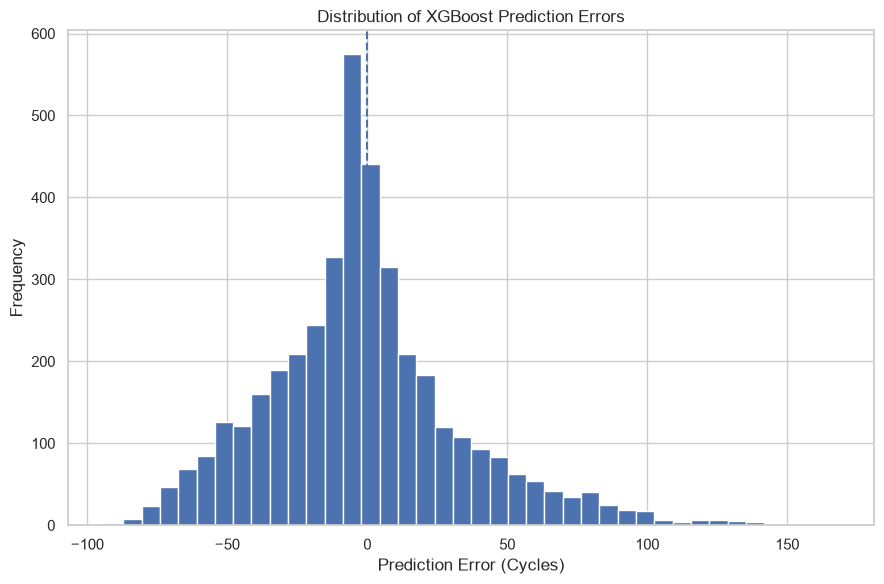

In [56]:
plt.figure(figsize=(9, 6))

plt.hist(errors, bins=40)

plt.axvline(
    0,
    linestyle="--"
)

plt.xlabel("Prediction Error (Cycles)")
plt.ylabel("Frequency")
plt.title("Distribution of XGBoost Prediction Errors")

plt.tight_layout()
plt.show()

In [57]:
# Engine-Level Performance

val_results = df.iloc[val_idx][["engine_id", "cycle"]].copy()

val_results["Actual_RUL"] = y_val.values
val_results["Predicted_RUL"] = y_pred_final
val_results["Absolute_Error"] = np.abs(
    val_results["Actual_RUL"] - val_results["Predicted_RUL"]
)

engine_performance = (
    val_results
    .groupby("engine_id")["Absolute_Error"]
    .mean()
    .reset_index()
    .rename(columns={"Absolute_Error": "MAE"})
)

engine_performance = engine_performance.sort_values("MAE")

print("Engine-Level MAE")
print("=" * 40)
display(engine_performance.round(2))

Engine-Level MAE


,engine_id,MAE
19,91,10.9200
8,34,12.7200
4,19,14.0700
3,13,16.4000
7,32,17.3800
13,71,18.4200
5,23,20.3000
2,11,20.6100
9,40,21.2100
12,54,21.8100


In [58]:
import joblib
from pathlib import Path

models_dir = Path("../models")
models_dir.mkdir(parents=True, exist_ok=True)

# Save XGBoost model
joblib.dump(
    final_model,
    models_dir / "xgboost_rul_model.pkl"
)

print("Final XGBoost model saved successfully.")

Final XGBoost model saved successfully.


In [59]:
joblib.dump(
    scaler,
    models_dir / "scaler.pkl"
)

print("Scaler saved successfully.")

Scaler saved successfully.


In [60]:
feature_names = X_train.columns.tolist()

joblib.dump(
    feature_names,
    models_dir / "feature_names.pkl"
)

print("Feature names saved successfully.")
print(feature_names)

Feature names saved successfully.
['sensor_2', 'sensor_3', 'sensor_4', 'sensor_6', 'sensor_7', 'sensor_8', 'sensor_9', 'sensor_11', 'sensor_12', 'sensor_13', 'sensor_14', 'sensor_15', 'sensor_17', 'sensor_20', 'sensor_21']


In [61]:
# Export validation metrics and provenance next to the model, so the app can only
# ever display metrics that belong to the exact model file it loads.
import json
import hashlib

model_path = models_dir / "xgboost_rul_model.pkl"

rul_bands = pd.cut(y_val, bins=[-1, 25, 50, 100, 150, 200, np.inf],
                   labels=["0-25", "26-50", "51-100", "101-150", "151-200", ">200"])
band_errors = (
    pd.DataFrame({"band": rul_bands, "error": y_pred_final - y_val})
    .groupby("band", observed=True)["error"]
    .agg(rows="size", MAE=lambda e: e.abs().mean(), bias="mean")
    .round(2)
    .reset_index()
)

model_metadata = {
    "model_file": model_path.name,
    "model_sha256": hashlib.sha256(model_path.read_bytes()).hexdigest(),
    "model_type": type(final_model).__name__,
    "model_name": "GroupKFold-tuned XGBoost",
    "features": feature_names,
    "target": "RUL = max_cycle(engine) - current_cycle",
    "input_scaling": "none (raw sensor values)",
    "hyperparameters": group_random_search.best_params_,
    "tuning": "RandomizedSearchCV, 20 candidates, 3-fold GroupKFold on the training engines, scoring = MAE",
    "groupkfold_cv_mae": round(float(-group_random_search.best_score_), 4),
    "validation": {
        "strategy": "GroupShuffleSplit by engine_id (test_size=0.20, random_state=42)",
        "train_engines": sorted(int(e) for e in train_engines),
        "validation_engines": sorted(int(e) for e in val_engines),
        "train_rows": int(len(X_train)),
        "validation_rows": int(len(X_val)),
    },
    "metrics": {
        "MAE": round(float(mae_xgb_group), 4),
        "RMSE": round(float(rmse_xgb_group), 4),
        "R2": round(float(r2_xgb_group), 4),
    },
    "error_by_rul_band": band_errors.astype({"band": str}).to_dict(orient="records"),
}

(models_dir / "model_metadata.json").write_text(json.dumps(model_metadata, indent=2), encoding="utf-8")

print("Model metadata saved successfully.")
print(json.dumps(model_metadata["metrics"], indent=2))
display(band_errors)


Model metadata saved successfully.
{
  "MAE": 25.8786,
  "RMSE": 35.1955,
  "R2": 0.7126
}


,band,rows,MAE,bias
0,0-25,520,6.4100,5.3100
1,26-50,500,16.6100,12.3900
2,51-100,1000,30.3400,24.5700
3,101-150,984,21.9400,11.9500
4,151-200,673,25.0000,-20.5900
5,>200,393,63.4200,-63.4200


# Final Model Summary

## Final Model Selection

After comparing Linear Regression, Random Forest, and XGBoost models,
XGBoost was selected as the model family based on its validation performance.

The validation set was separated at the engine level (20 of the 100 engines)
so that no engine appears in both training and validation data.

### Final Model: GroupKFold-Tuned XGBoost

The hyperparameters of the final model were selected with `RandomizedSearchCV`
(20 candidates) using 3-fold `GroupKFold` on the 80 training engines only,
so cycles from the same engine were never split across folds and the
20 validation engines were not used for tuning.

Best hyperparameters: `n_estimators=400`, `max_depth=4`, `learning_rate=0.01`,
`subsample=0.7`, `colsample_bytree=0.7`, `min_child_weight=5`, `gamma=0.1`.

Validation performance (20 held-out engines, 4,070 rows):

- MAE: 25.8786 cycles
- RMSE: 35.1955 cycles
- R²: 0.7126

For reference, the untuned baseline XGBoost (hand-picked hyperparameters)
scored MAE 25.6385 / RMSE 35.2748 / R² 0.7113. The difference is not
meaningful; the GroupKFold-tuned model was chosen because its
hyperparameters were selected without looking at the validation engines.

### Saved Model Files

Saved in the `models/` directory:

- `xgboost_rul_model.pkl` — the final GroupKFold-tuned XGBoost model (raw, unscaled sensor values)
- `feature_names.pkl` — the 15 input features in model order
- `model_metadata.json` — validation metrics, hyperparameters, engine split and a SHA-256 fingerprint of the model file
- `scaler.pkl` — the StandardScaler used only by the Linear Regression comparison; XGBoost does **not** use it

### Known Limitations

- Each prediction uses a single cycle of sensor readings, so predictions are noisy.
- RUL is not capped, so early-life RUL (when sensors are still flat) is hard to predict
  and is systematically under-estimated for engines with very long remaining life.
- The official test set (`test_FD001.txt` + `RUL_FD001.txt`) has not been evaluated yet.


In [62]:
# Final Model Files Verification
# Reload the saved artifacts from disk and confirm they reproduce the reported results.

loaded_model = joblib.load(models_dir / "xgboost_rul_model.pkl")
loaded_features = joblib.load(models_dir / "feature_names.pkl")
loaded_metadata = json.loads((models_dir / "model_metadata.json").read_text(encoding="utf-8"))

assert type(loaded_model).__name__ == "XGBRegressor"
assert list(loaded_model.feature_names_in_) == loaded_features == feature_names
loaded_params = loaded_model.get_params()
assert {k: loaded_params[k] for k in group_random_search.best_params_} == group_random_search.best_params_

y_pred_loaded = loaded_model.predict(X_val[loaded_features])
assert np.array_equal(y_pred_loaded, y_pred_final), "Reloaded model predictions differ."

reloaded_metrics = {
    "MAE": round(float(mean_absolute_error(y_val, y_pred_loaded)), 4),
    "RMSE": round(float(np.sqrt(mean_squared_error(y_val, y_pred_loaded))), 4),
    "R2": round(float(r2_score(y_val, y_pred_loaded)), 4),
}
assert reloaded_metrics == loaded_metadata["metrics"], "Saved metrics do not match the saved model."
assert hashlib.sha256((models_dir / "xgboost_rul_model.pkl").read_bytes()).hexdigest() == loaded_metadata["model_sha256"]

print("Final Model Files")
print("=" * 40)
for file in ["xgboost_rul_model.pkl", "feature_names.pkl", "model_metadata.json", "scaler.pkl"]:
    print(f"{file}: {'OK' if (models_dir / file).exists() else 'MISSING'}")

print("\nReloaded model validation metrics:", reloaded_metrics)
print("Hyperparameters:", loaded_metadata["hyperparameters"])


Final Model Files
xgboost_rul_model.pkl: OK
feature_names.pkl: OK
model_metadata.json: OK
scaler.pkl: OK

Reloaded model validation metrics: {'MAE': 25.8786, 'RMSE': 35.1955, 'R2': 0.7126}
Hyperparameters: {'subsample': 0.7, 'n_estimators': 400, 'min_child_weight': 5, 'max_depth': 4, 'learning_rate': 0.01, 'gamma': 0.1, 'colsample_bytree': 0.7}
